# Hız Cezası Tahmini: Ceza Yer miyim, Yersem Ne Kadar?

**Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine** · Yapay Zeka İçin Basitleştirilmiş Python

Bu not defteri, bir sürücünün radara yakalandığında hız cezası alıp almayacağını, alırsa kaç TL ödeyeceğini ve ehliyetinin geri alınıp alınmayacağını tahmin eden küçük bir yapay zekâ uygulamasıdır. Problem tanımından mini uygulamaya kadar her adım burada çalışır.

## Aşama 1: Problem Tanımı

| Proje Tanım Formu | |
|---|---|
| Problem cümlesi | Araç tipi, yol tipi ve radarın ölçtüğü hızdan sürücünün ceza alıp almayacağını ve cezanın tutarını tahmin et. |
| Hedef değişken | `ceza_tutari_tl` (0 TL = ceza yok) |
| Problem türü | Sınıflandırma: her ceza tutarı bir sınıf |

**Neden önemli?** 2026'da hız cezaları sınırın kaç km/s aşıldığına göre 9 kademeye bağlandı: ceza 2.000 TL ile 30.000 TL arasında ve yüksek aşımlarda ehliyet 30 ile 90 gün geri alınıyor. Birçok sürücü "sınırı 8 km/s aşsam ne olur?" sorusunun cevabını bilmeyebilir. Bu tahmin, yola çıkmadan önce riskini görmek isteyen sürücüye, öğrencisine kuralları anlatan sürücü kursuna ve şoförlerini eğiten filo yöneticisine yarar.

**Veri neden üretildi, model ne gösteriyor?** Kişi bazında gerçek ceza kayıtları kamuya açık değil; yönerge veri setinin katılımcı tarafından oluşturulmasına izin veriyor. Ceza, kanunda kesin bir kurala bağlı olduğu için doğru cevap belli ve bu, gerçek veride yapılamayan bir sınavı mümkün kılıyor: modelin örneklerden öğrendiği kuralı kanunun kendisiyle birebir karşılaştırmak. Proje bu sayede iki soruya cevap arıyor: model hangi bilgiyle kuralı doğru öğreniyor ve kaç örnek yetiyor?

In [ ]:
# Setup: in Colab the project files are fetched from the public repository, locally they are already here.
import os
import subprocess
import sys

REPO_URL = "https://github.com/AxelXoket/speeding-fine-predictor.git"
if not os.path.isdir("speeding_fine"):
    if not os.path.isdir("speeding-fine-predictor"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("speeding-fine-predictor")
sys.path.insert(0, os.getcwd())

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

from speeding_fine import dataset, rules

os.makedirs("figures", exist_ok=True)
pd.set_option("display.width", 120)
# Large type, because the figures are also printed small in the one-page report.
plt.rcParams.update({"font.size": 12})


def percent_tr(value):
    """Turkish percent with a decimal comma: 0.865 -> '%86,5', 1.0 -> '%100'."""
    text = f"{value * 100:.1f}"
    return "%" + (text[:-2] if text.endswith(".0") else text).replace(".", ",")


def tl_tr(value):
    """Whole number with a Turkish thousands point: 20000 -> '20.000'."""
    return f"{value:,.0f}".replace(",", ".")


print("Hazır. Çalışma klasörü:", os.path.basename(os.getcwd()))

Hazır. Çalışma klasörü: speeding-fine-predictor


## Aşama 2: Veri Toplama ve Hazırlama

**Veri nereden geliyor?** Veri setini kendim oluşturdum. Araç tipi, yol tipi ve ölçülen hız rastgele seçildi. Ceza tutarı 2918 sayılı Karayolları Trafik Kanunu'nun (KTK) 51. maddesinin 2. fıkrasındaki 2026 kademelerinden (7574 sayılı Kanun, Resmî Gazete 27.02.2026), ehliyet yaptırımı aynı maddenin 3. ve 4. fıkralarından hesaplandı. Hız sınırları, Karayolları Trafik Yönetmeliği'nin 100. maddesindeki römorksuz araçlar için geçerli varsayılan değerlerdir. Kurallar [`speeding_fine/rules.py`](https://github.com/AxelXoket/speeding-fine-predictor/blob/main/speeding_fine/rules.py), veriyi üreten kod [`speeding_fine/dataset.py`](https://github.com/AxelXoket/speeding-fine-predictor/blob/main/speeding_fine/dataset.py) dosyasında; kaynaklar README'de.

Gerçek kayıtlar çoğu zaman temiz gelmez. Temizleme adımının gerçek bir işi olsun diye satırların küçük bir kısmı bilerek bozuldu: boş hız, imkânsız hız, boş hava durumu, büyük harf ve boşluk karışmış metin, iki kez girilmiş kayıt.

**Veri sözlüğü**

| Sütun | Tip | Anlamı ve değerleri |
|---|---|---|
| `kayit_no` | sayısal | Radar kaydının numarası |
| `arac_tipi` | kategorik | `otomobil`, `panelvan`, `kamyonet`, `motosiklet` (L3 sınıfı), `minibus`, `otobus`, `kamyon` |
| `yol_tipi` | kategorik | `yerlesim_yeri`, `sehirlerarasi_cift_yonlu`, `bolunmus_yol`, `otoyol` |
| `hiz_siniri` | sayısal (km/s) | O araç ve yol için yasal sınır |
| `olculen_hiz` | sayısal (km/s) | Radarın ölçtüğü hız |
| `saat` | sayısal (0-23) | Ölçüm saati |
| `hava` | kategorik | `acik`, `yagmurlu`, `sisli`, `karli`; temizlikte boş olanlar `bilinmiyor` olur |
| `ceza_tutari_tl` | kategorik (hedef, 10 sınıf) | Kesilen ceza (TL): 0 ya da 9 kademe tutarından biri; her tutar bir sınıf |
| `ehliyet_geri_alma_gun` | sayısal | Sürücü belgesinin geri alındığı gün sayısı |

**Etiketlerin geldiği ceza tablosu** (KTK 51/2, 51/3 ve 51/4; `speeding_fine/rules.py` dosyasından basılıyor). Yerleşim yeri içi ve dışı için 9'ar kademe var; bir kademenin başladığı km/s değerine bu projede **kademe sınırı** diyorum, toplam 18 kademe sınırı.

In [ ]:
def tier_range(tier):
    return f"{tier.min_excess}-{tier.max_excess}" if tier.max_excess else f"{tier.min_excess} ve üstü"


pd.DataFrame(
    {
        "Aşım, yerleşim yeri içi (km/s)": [tier_range(t) for t in rules.URBAN_TIERS],
        "Aşım, yerleşim yeri dışı (km/s)": [tier_range(t) for t in rules.RURAL_TIERS],
        "Ceza (TL)": [tl_tr(t.fine_tl) for t in rules.URBAN_TIERS],
        "Ehliyet geri alma (gün)": [t.suspension_days or "" for t in rules.URBAN_TIERS],
    },
    index=range(1, len(rules.URBAN_TIERS) + 1),
)

,"Aşım, yerleşim yeri içi (km/s)","Aşım, yerleşim yeri dışı (km/s)",Ceza (TL),Ehliyet geri alma (gün)
1,6-10,11-15,2.000,
2,11-15,16-20,4.000,
3,16-20,21-25,6.000,
4,21-25,26-30,8.000,
5,26-35,31-40,12.000,
6,36-45,41-50,15.000,
7,46-55,51-60,20.000,30
8,56-65,61-70,25.000,60
9,66 ve üstü,71 ve üstü,30.000,90


In [ ]:
raw = pd.read_csv("data/speeding_records.csv")
print("Satır, sütun:", raw.shape)
raw.head()

Satır, sütun: (608, 9)


,kayit_no,arac_tipi,yol_tipi,hiz_siniri,olculen_hiz,saat,hava,ceza_tutari_tl,ehliyet_geri_alma_gun
0,231,otomobil,otoyol,120,145.0,3,yagmurlu,6000,0
1,480,otobus,yerlesim_yeri,50,31.0,11,sisli,0,0
2,122,kamyon,sehirlerarasi_cift_yonlu,80,105.0,4,acik,6000,0
3,385,otomobil,yerlesim_yeri,50,56.0,18,yagmurlu,2000,0
4,511,otomobil,otoyol,120,116.0,3,yagmurlu,0,0


In [ ]:
# Look for the usual problems before trusting the data: blanks, repeated rows, inconsistent spelling.
print(raw.isnull().sum())
print("Tekrarlanan satır:", raw.duplicated().sum())
print()
print(raw["yol_tipi"].value_counts().to_string())
raw["arac_tipi"].value_counts()

kayit_no                  0
arac_tipi                 0
yol_tipi                  0
hiz_siniri                0
olculen_hiz               6
saat                      0
hava                     15
ceza_tutari_tl            0
ehliyet_geri_alma_gun     0
dtype: int64
Tekrarlanan satır: 8

yol_tipi
yerlesim_yeri                246
bolunmus_yol                 142
sehirlerarasi_cift_yonlu     119
otoyol                        95
Otoyol                         1
 Sehirlerarasi_cift_yonlu      1
Yerlesim_Yeri                  1
 Yerlesim_yeri                 1
SEHIRLERARASI_CIFT_YONLU       1
BOLUNMUS_YOL                   1


arac_tipi
otomobil       293
kamyon          85
kamyonet        76
motosiklet      47
panelvan        37
otobus          32
minibus         32
 Otomobil        2
Otomobil         2
MOTOSIKLET       1
OTOMOBIL         1
Name: count, dtype: int64

Sorunlar görünüyor: `olculen_hiz` ve `hava` sütunlarında boş değerler var, bazı satırlar iki kez girilmiş, araç ve yol tipleri bazı satırlarda büyük harfle ya da başında ve sonunda boşlukla yazılmış. Temizleme adımları:

1. Metin sütunlarında baştaki ve sondaki boşluklar silinir, harfler küçültülür.
2. Aynı kaydın ikinci kopyası silinir.
3. Boş hava durumu "bilinmiyor" ile doldurulur; ceza hava durumuna bağlı değil, satır atılmaz.
4. Hızı boş olan kayıt silinir; hız olmadan ceza hesaplanamaz.
5. Sıfır, eksi ya da 300 km/s üstü gibi fiziksel olarak imkânsız hızlar silinir.

In [ ]:
clean = raw.copy()
# Spelling first, so that rows that differ only by spelling are recognised as the same value.
spelling_fixed = 0
for column in ["arac_tipi", "yol_tipi"]:
    fixed = clean[column].str.strip().str.lower()
    spelling_fixed += int((fixed != clean[column]).sum())
    clean[column] = fixed
print("Yazımı düzeltilen değer:", spelling_fixed)
clean = clean.drop_duplicates()
# Weather does not change the fine, so a blank weather value is filled instead of losing the row.
clean["hava"] = clean["hava"].fillna("bilinmiyor")
# Without a speed there is nothing to judge, so these rows go.
clean = clean.dropna(subset=["olculen_hiz"])

possible_speed = clean["olculen_hiz"].between(1, rules.MAX_PLAUSIBLE_SPEED)
print("Silinen imkânsız hızlar:", [int(s) for s in clean.loc[~possible_speed, "olculen_hiz"]])
clean = clean[possible_speed].copy()
clean["olculen_hiz"] = clean["olculen_hiz"].astype(int)
clean = clean.reset_index(drop=True)

print(f"Temizlikten önce {len(raw)} satır, sonra {len(clean)} satır")
print("Kalan boş değer:", int(clean.isnull().sum().sum()))
clean["arac_tipi"].value_counts()

Yazımı düzeltilen değer: 12
Silinen imkânsız hızlar: [412, 0, -48]
Temizlikten önce 608 satır, sonra 591 satır
Kalan boş değer: 0


arac_tipi
otomobil      292
kamyon         83
kamyonet       73
motosiklet     46
panelvan       36
minibus        31
otobus         30
Name: count, dtype: int64

## Aşama 3: Keşifçi Veri Analizi ve Görselleştirme

Cezayı belirleyen şeyin hızın kendisi değil, sınırın ne kadar aşıldığı olduğundan şüpheleniyorum. Bunu görmek için iki yeni sütun ekliyorum: `asim_km` (ölçülen hız eksi sınır) ve `yerlesim_ici` (yerleşim yeri içiyse 1).

In [ ]:
def add_features(frame):
    """Add the excess over the limit and the urban flag that the fine rules depend on."""
    frame = frame.copy()
    frame["asim_km"] = frame["olculen_hiz"] - frame["hiz_siniri"]
    frame["yerlesim_ici"] = (frame["yol_tipi"] == rules.URBAN_ROAD).astype(int)
    return frame


def weather_label(code):
    return dataset.WEATHER_LABELS.get(code, code.capitalize())


clean = add_features(clean)
clean["ceza_var"] = (clean["ceza_tutari_tl"] > 0).astype(int)
clean[["hiz_siniri", "olculen_hiz", "asim_km", "ceza_tutari_tl", "ehliyet_geri_alma_gun"]].describe().round(1)

,hiz_siniri,olculen_hiz,asim_km,ceza_tutari_tl,ehliyet_geri_alma_gun
count,591.0,591.0,591.0,591.0,591.0
mean,77.8,89.0,11.2,5198.0,6.6
std,25.2,36.0,25.8,8038.4,20.7
min,50.0,25.0,-25.0,0.0,0.0
25%,50.0,63.0,-9.0,0.0,0.0
50%,85.0,90.0,9.0,2000.0,0.0
75%,95.0,113.0,23.0,6000.0,0.0
max,120.0,206.0,93.0,30000.0,90.0


In [ ]:
print("Ceza tutarına göre kayıt sayısı:")
print(clean["ceza_tutari_tl"].value_counts().sort_index().rename(index=tl_tr).to_string())
print()
road = clean.groupby("yol_tipi").agg(oran=("ceza_var", "mean"), ortalama=("ceza_tutari_tl", "mean"), kayit=("ceza_var", "size"))
print("Yol tipine göre ceza alan kayıtların oranı ve ortalama ceza:")
for code, row in road.reindex(rules.ROAD_TYPES).iterrows():
    print(f"  {rules.ROAD_LABELS[code]:<30} {percent_tr(row['oran']):>6}   ortalama {tl_tr(row['ortalama']):>6} TL   ({row['kayit']:.0f} kayıt)")
print()
# The group size matters: a rate measured on 20 rows moves a lot by chance.
weather = clean.groupby("hava")["ceza_var"].agg(["mean", "size"]).rename(columns={"mean": "ceza oranı", "size": "kayıt sayısı"})
print("Hava durumuna göre ceza alan kayıtların oranı:")
for code, row in weather.sort_values("kayıt sayısı", ascending=False).iterrows():
    print(f"  {weather_label(code):<12} {percent_tr(row['ceza oranı']):>6}   ({row['kayıt sayısı']:.0f} kayıt)")
print()
# Where fines start on each side: the largest excess that went unfined and the smallest excess that was fined.
fine_start = clean.groupby(["yerlesim_ici", "ceza_var"])["asim_km"].agg(["min", "max"])
print("Cezanın başladığı yer:")
for urban, label in [(1, "Yerleşim yeri içi"), (0, "Yerleşim yeri dışı")]:
    print(f"  {label:<18} ceza almayan en büyük aşım {fine_start.loc[(urban, 0), 'max']:.0f} km/s, "
          f"ceza alan en küçük aşım {fine_start.loc[(urban, 1), 'min']:.0f} km/s")
print()
# The generator ignores speed limiters, so count the rows a working limiter would not allow (see the weak points below).
limiter = clean["arac_tipi"].map(rules.SPEED_LIMITER)
limiter_rows = int((clean["olculen_hiz"] > limiter).sum())
limiter_speeds = ", ".join(f"{rules.VEHICLE_LABELS[v].lower()} {s}" for v, s in rules.SPEED_LIMITER.items())
print(f"Hız sınırlayıcının izin vermediği hızda kayıt ({limiter_speeds} km/s üstü): {limiter_rows}")

Ceza tutarına göre kayıt sayısı:
ceza_tutari_tl
0         289
2.000      57
4.000      50
6.000      54
8.000      39
12.000     21
15.000     15
20.000     25
25.000     17
30.000     24

Yol tipine göre ceza alan kayıtların oranı ve ortalama ceza:
  Yerleşim yeri içi               %54,6   ortalama  5.975 TL   (240 kayıt)
  Şehirlerarası çift yönlü yol    %46,6   ortalama  4.661 TL   (118 kayıt)
  Bölünmüş yol                    %52,5   ortalama  4.816 TL   (141 kayıt)
  Otoyol                          %45,7   ortalama  4.446 TL   (92 kayıt)

Hava durumuna göre ceza alan kayıtların oranı:
  Açık          %50,2   (412 kayıt)
  Yağmurlu      %55,2   (96 kayıt)
  Sisli         %40,9   (44 kayıt)
  Karlı         %62,5   (24 kayıt)
  Bilinmiyor      %60   (15 kayıt)

Cezanın başladığı yer:
  Yerleşim yeri içi  ceza almayan en büyük aşım 5 km/s, ceza alan en küçük aşım 6 km/s
  Yerleşim yeri dışı ceza almayan en büyük aşım 10 km/s, ceza alan en küçük aşım 11 km/s

Hız sınırlayıcının izin ve

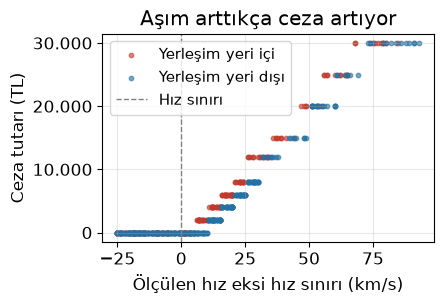

In [ ]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
for urban, label, color in [(1, "Yerleşim yeri içi", "#c0392b"), (0, "Yerleşim yeri dışı", "#2471a3")]:
    part = clean[clean["yerlesim_ici"] == urban]
    ax.scatter(part["asim_km"], part["ceza_tutari_tl"], s=10, alpha=0.6, color=color, label=label)
ax.axvline(0, color="gray", linestyle="--", linewidth=1, label="Hız sınırı")
ax.set_title("Aşım arttıkça ceza artıyor")
ax.set_xlabel("Ölçülen hız eksi hız sınırı (km/s)")
ax.set_ylabel("Ceza tutarı (TL)")
ax.yaxis.set_major_formatter(lambda value, _: tl_tr(value))
ax.legend(fontsize=11, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/asim_ceza.png", dpi=240)
plt.show()

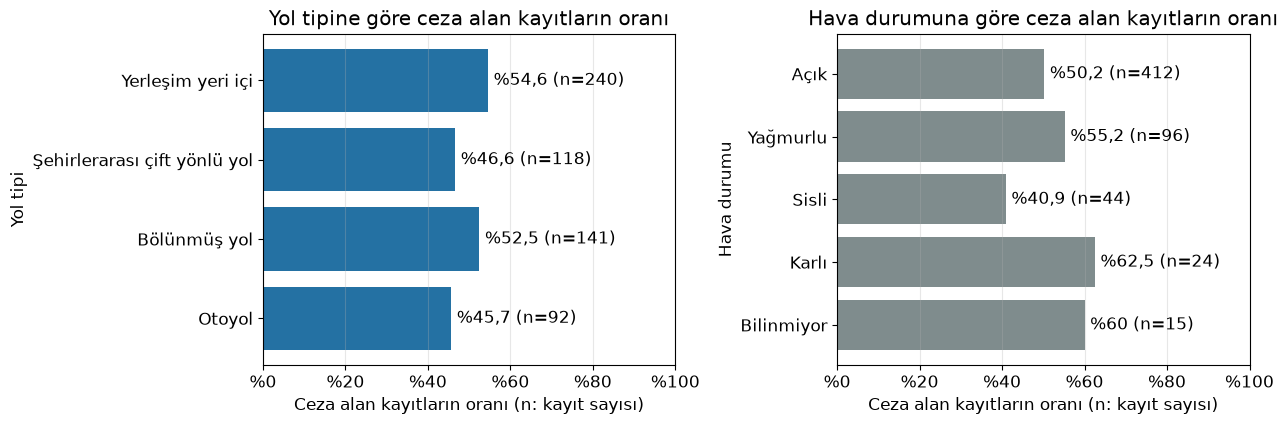

In [ ]:
# Horizontal bars keep every category name on one line.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
by_road = road.reindex(rules.ROAD_TYPES[::-1])
bars = axes[0].barh([rules.ROAD_LABELS[code] for code in by_road.index], by_road["oran"], color="#2471a3")
axes[0].bar_label(bars, labels=[f"{percent_tr(r)} (n={n:.0f})" for r, n in zip(by_road["oran"], by_road["kayit"])], padding=4)
axes[0].set_title("Yol tipine göre ceza alan kayıtların oranı")
axes[0].set_ylabel("Yol tipi")
by_weather = weather.sort_values("kayıt sayısı")
bars = axes[1].barh([weather_label(code) for code in by_weather.index], by_weather["ceza oranı"], color="#7f8c8d")
axes[1].bar_label(bars, labels=[f"{percent_tr(r)} (n={n})" for r, n in zip(by_weather["ceza oranı"], by_weather["kayıt sayısı"])], padding=4)
axes[1].set_title("Hava durumuna göre ceza alan kayıtların oranı")
axes[1].set_ylabel("Hava durumu")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_xlabel("Ceza alan kayıtların oranı (n: kayıt sayısı)")
    ax.xaxis.set_major_formatter(lambda value, _: f"%{value * 100:.0f}")
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("figures/ceza_orani.png", dpi=160)
plt.show()

**Keşif bulguları**

1. Ceza, aşım arttıkça basamak basamak yükseliyor; her basamak kanundaki bir km/s aralığına karşılık geliyor.
2. Yerleşim yeri içinde ceza daha küçük aşımda başlıyor: içeride 6 km/s aşım ceza getirirken dışarıda en az 11 km/s aşım gerekiyor (yukarıdaki "Cezanın başladığı yer" çıktısı).
3. Sınırın altında kalan ya da sınırı yerleşim yeri içinde en çok 5, dışında en çok 10 km/s aşan kayıtların hiçbiri ceza almıyor.
4. Hava durumuna göre ceza oranları farklı görünüyor, ama en yüksek ve en düşük oranlar, kayıt sayısı en büyük grubun dörtte birinden az olan gruplarda. Veri hava durumundan bağımsız üretildi ve kanunda hava ceza tutarını değiştirmiyor; bu farklar az sayıda kayıttan gelen rastlantı.
5. Belirleyici olan iki şey var: sınırın kaç km/s aşıldığı ve yerleşim yeri içinde olup olmadığı.

## Aşama 4: Model Kurma ve Eğitme

İki model kuruyorum ve karşılaştırıyorum:

- **Model A (ham):** veri setindeki sütunlar olduğu gibi: araç tipi, yol tipi, hava, hız sınırı, ölçülen hız, saat. Üç metin sütunu her değer için ayrı bir 0/1 sütununa açıldığından modelin gördüğü sütun sayısı daha fazla (aşağıdaki çıktıda).
- **Model B (aşım):** keşifte belirleyici çıkan iki sütun, `asim_km` ve `yerlesim_ici`.

**Neden karar ağacı?** Kanun bir eşik merdiveni ve karar ağacı da tam olarak "bu değer şu eşikten küçük mü?" sorularıyla çalışıyor. Öğrendiği eşikler okunabildiği için modelin kanunu bulup bulmadığı doğrudan görülebiliyor. Çıktı belirli tutarlardan biri olduğu için sınıflandırma kullanıyorum.

In [ ]:
TARGET = "ceza_tutari_tl"
ENGINEERED = ["asim_km", "yerlesim_ici"]


def raw_matrix(frame, columns=None):
    """One-hot encode the text columns; align to the training columns when they are given."""
    matrix = pd.get_dummies(frame[["arac_tipi", "yol_tipi", "hava"]]).join(frame[["hiz_siniri", "olculen_hiz", "saat"]])
    return matrix if columns is None else matrix.reindex(columns=columns, fill_value=False)


X_raw = raw_matrix(clean)
X_eng = clean[ENGINEERED]
y = clean[TARGET]
# One split for both models, so they are judged on exactly the same rows; stratify keeps rare fines in the test set.
X_raw_train, X_raw_test, X_eng_train, X_eng_test, y_train, y_test = train_test_split(
    X_raw, X_eng, y, test_size=0.25, random_state=42, stratify=y
)
print("Model A  eğitim:", X_raw_train.shape, " test:", X_raw_test.shape)
print("Model B  eğitim:", X_eng_train.shape, " test:", X_eng_test.shape)

raw_model = DecisionTreeClassifier(random_state=42).fit(X_raw_train, y_train)
model = DecisionTreeClassifier(random_state=42).fit(X_eng_train, y_train)
print("İki model de eğitildi.")

Model A  eğitim: (443, 19)  test: (148, 19)
Model B  eğitim: (443, 2)  test: (148, 2)
İki model de eğitildi.


## Aşama 5: Tahmin ve Değerlendirme

Önce test verisindeki doğruluk. Sonra daha sert bir sınav: modeli kanunun kendisiyle karşılaştırıyorum. Her araç tipi, her yol tipi ve sınırın 25 km/s altından 95 km/s üstüne kadar her hız için kanunun verdiği ceza ile modelin tahmini aynı mı? **Kanunla uyum**, aynı cezanın verildiği durumların oranıdır. Model A hava ve saat de istediği için bu tabloda hava açık, saat 12 alındı; kanunda ceza bunlara bağlı değil.

In [ ]:
results = {}
for name, fitted, train_X, test_X in [("Model A (ham)", raw_model, X_raw_train, X_raw_test), ("Model B (aşım)", model, X_eng_train, X_eng_test)]:
    results[name] = {
        "train_accuracy": accuracy_score(y_train, fitted.predict(train_X)),
        "test_accuracy": accuracy_score(y_test, fitted.predict(test_X)),
    }

# Every vehicle, road and speed from 25 km/h under to 95 km/h over the limit, judged by the law itself.
grid = pd.DataFrame(
    [
        (vehicle, road_type, rules.speed_limit(vehicle, road_type), rules.speed_limit(vehicle, road_type) + excess)
        for vehicle in rules.VEHICLE_TYPES
        for road_type in rules.ROAD_TYPES
        for excess in range(-25, 96)
    ],
    columns=["arac_tipi", "yol_tipi", "hiz_siniri", "olculen_hiz"],
).assign(hava="acik", saat=12)
grid = add_features(grid)
grid["law"] = [rules.penalty_for(v, r, s).fine_tl for v, r, s in zip(grid["arac_tipi"], grid["yol_tipi"], grid["olculen_hiz"])]
grid["model_a"] = raw_model.predict(raw_matrix(grid, X_raw_train.columns))
grid["model_b"] = model.predict(grid[ENGINEERED])
results["Model A (ham)"]["law_agreement"] = (grid["model_a"] == grid["law"]).mean()
results["Model B (aşım)"]["law_agreement"] = (grid["model_b"] == grid["law"]).mean()

summary = pd.DataFrame(results).T.rename(columns={"train_accuracy": "Eğitim doğruluğu", "test_accuracy": "Test doğruluğu", "law_agreement": "Kanunla uyum"})
print("Kanunla karşılaştırılan durum sayısı:", tl_tr(len(grid)))
summary.map(percent_tr)

Kanunla karşılaştırılan durum sayısı: 3.388


,Eğitim doğruluğu,Test doğruluğu,Kanunla uyum
Model A (ham),%100,"%86,5","%76,3"
Model B (aşım),%100,"%99,3","%96,9"


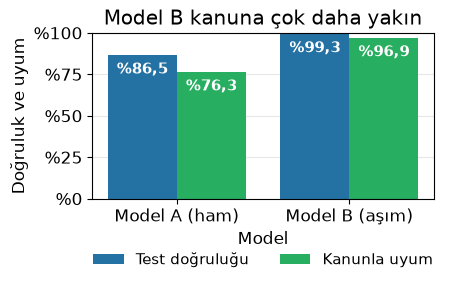

In [ ]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
positions = range(len(summary))
ax.bar([p - 0.2 for p in positions], summary["Test doğruluğu"], width=0.4, label="Test doğruluğu", color="#2471a3")
ax.bar([p + 0.2 for p in positions], summary["Kanunla uyum"], width=0.4, label="Kanunla uyum", color="#27ae60")
# Values sit inside the bars, so no grid line or edge runs through them.
for p, (test_acc, law_acc) in zip(positions, summary[["Test doğruluğu", "Kanunla uyum"]].values):
    ax.text(p - 0.2, test_acc - 0.04, percent_tr(test_acc), ha="center", va="top", color="white", fontsize=11, fontweight="bold")
    ax.text(p + 0.2, law_acc - 0.04, percent_tr(law_acc), ha="center", va="top", color="white", fontsize=11, fontweight="bold")
ax.set_xticks(list(positions), summary.index)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"%{value * 100:.0f}")
ax.set_title("Model B kanuna çok daha yakın")
ax.set_xlabel("Model")
ax.set_ylabel("Doğruluk ve uyum")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False, fontsize=11)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("figures/model_karsilastirma.png", dpi=240)
plt.show()

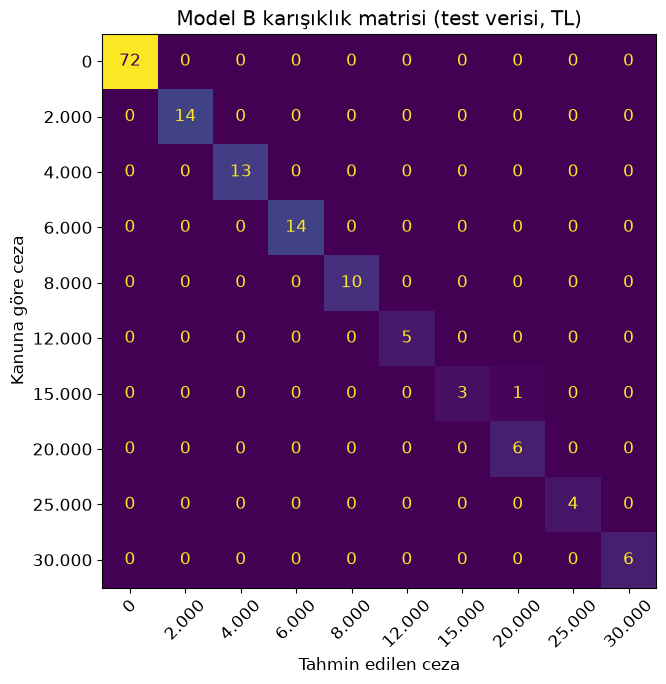

Test verisindeki 148 kaydın 1 tanesi yanlış tahmin edildi:
  kanuna göre 15.000 TL olan 1 kayıt için 20.000 TL tahmin edildi


In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
fine_classes = sorted(y.unique())
ConfusionMatrixDisplay.from_predictions(
    y_test, model.predict(X_eng_test), labels=fine_classes, ax=ax, colorbar=False, xticks_rotation=45,
    display_labels=[tl_tr(c) for c in fine_classes],
)
ax.set_title("Model B karışıklık matrisi (test verisi, TL)")
ax.set_xlabel("Tahmin edilen ceza")
ax.set_ylabel("Kanuna göre ceza")
fig.tight_layout()
fig.savefig("figures/karisiklik_matrisi.png", dpi=160)
plt.show()

# Off-diagonal cells are the mistakes; list them in words.
pairs = pd.DataFrame({"law": y_test.to_numpy(), "predicted": model.predict(X_eng_test)})
wrong = pairs[pairs["law"] != pairs["predicted"]].value_counts()
print(f"Test verisindeki {len(pairs)} kaydın {int(wrong.sum())} tanesi yanlış tahmin edildi:")
for (law_fine, predicted), count in wrong.items():
    print(f"  kanuna göre {tl_tr(law_fine)} TL olan {count} kayıt için {tl_tr(predicted)} TL tahmin edildi")

**Model kuralı mı öğrendi?** Bunu iki ölçümle sınıyorum. Birincisi kademe sınırları: bir sınırı **tam yerinde bulmak**, sınırın bir altındaki ve kendisindeki km/s değerinde kanunla aynı cezayı vermek demek. İkincisi eğitimde hiç görülmemiş girdiler: Model B yalnız (aşım, yerleşim yeri içi mi) çiftini gördüğü için, eğitim satırlarında hiç geçmeyen çiftlerdeki uyum, ezberin değil kuralın ölçüsü.

In [ ]:
# Where does Model B disagree with the law? Model B only sees (excess, urban flag), so group the cases by that pair.
disagree = grid["model_b"] != grid["law"]
mistake_points = sorted(set(zip(grid.loc[disagree, "yerlesim_ici"], grid.loc[disagree, "asim_km"])))
print(f"Model B, {tl_tr(len(grid))} durumun {int(disagree.sum())} tanesinde kanundan ayrılıyor. Hepsi şu aşım değerlerinde:")
tier_starts = {1: [tier.min_excess for tier in rules.URBAN_TIERS], 0: [tier.min_excess for tier in rules.RURAL_TIERS]}
mistake_distances = []
for urban, excess in mistake_points:
    nearest = min(tier_starts[urban], key=lambda start: abs(excess - start))
    mistake_distances.append(abs(int(excess) - nearest))
    place = "yerleşim yeri içi" if urban else "yerleşim yeri dışı"
    print(f"  {place}, {int(excess)} km/s aşım: en yakın kademe sınırı {nearest} km/s, uzaklık {mistake_distances[-1]} km/s")
distinct_inputs = len(grid[ENGINEERED].drop_duplicates())
print(f"Model B yalnız (aşım, yerleşim yeri içi mi) çiftini gördüğü için bu durumlar {distinct_inputs} farklı girdiye iniyor; "
      f"kanundan ayrıldığı farklı girdi {len(mistake_points)}.")

# A tier boundary counts as found when the model agrees with the law on both sides of it.
correct_at = (~disagree).groupby([grid["yerlesim_ici"], grid["asim_km"]]).all()
boundaries = [(1, tier.min_excess) for tier in rules.URBAN_TIERS] + [(0, tier.min_excess) for tier in rules.RURAL_TIERS]
found = [(urban, start) for urban, start in boundaries if correct_at[(urban, start - 1)] and correct_at[(urban, start)]]
print(f"Kanundaki {len(boundaries)} kademe sınırından {len(found)} tanesini ağaç tam yerinde buldu.")

# The real test of learning a rule: inputs whose (excess, urban flag) pair never appeared in the training rows.
unseen = ~pd.MultiIndex.from_frame(grid[ENGINEERED]).isin(pd.MultiIndex.from_frame(X_eng_train))
unseen_agreement = (grid.loc[unseen, "model_b"] == grid.loc[unseen, "law"]).mean()
seen_agreement = (grid.loc[~unseen, "model_b"] == grid.loc[~unseen, "law"]).mean()
print(f"Eğitimde görülmüş girdilerde kanunla uyum: {percent_tr(seen_agreement)}.")
print(f"Eğitimde hiç görülmemiş girdi payı: {percent_tr(unseen.mean())}. Bu girdilerde kanunla uyum: {percent_tr(unseen_agreement)}.")
print()
print("Model B'nin öğrendiği eşikler:")
print(export_text(model, feature_names=ENGINEERED))

Model B, 3.388 durumun 105 tanesinde kanundan ayrılıyor. Hepsi şu aşım değerlerinde:
  yerleşim yeri dışı, 31 km/s aşım: en yakın kademe sınırı 31 km/s, uzaklık 0 km/s
  yerleşim yeri dışı, 49 km/s aşım: en yakın kademe sınırı 51 km/s, uzaklık 2 km/s
  yerleşim yeri dışı, 50 km/s aşım: en yakın kademe sınırı 51 km/s, uzaklık 1 km/s
  yerleşim yeri dışı, 71 km/s aşım: en yakın kademe sınırı 71 km/s, uzaklık 0 km/s
  yerleşim yeri içi, 46 km/s aşım: en yakın kademe sınırı 46 km/s, uzaklık 0 km/s
  yerleşim yeri içi, 66 km/s aşım: en yakın kademe sınırı 66 km/s, uzaklık 0 km/s
  yerleşim yeri içi, 67 km/s aşım: en yakın kademe sınırı 66 km/s, uzaklık 1 km/s
Model B yalnız (aşım, yerleşim yeri içi mi) çiftini gördüğü için bu durumlar 242 farklı girdiye iniyor; kanundan ayrıldığı farklı girdi 7.
Kanundaki 18 kademe sınırından 13 tanesini ağaç tam yerinde buldu.
Eğitimde görülmüş girdilerde kanunla uyum: %100.
Eğitimde hiç görülmemiş girdi payı: %30,2. Bu girdilerde kanunla uyum: %89,7.

Mod

Hatalar kademe sınırlarının yanında toplanıyor. Bunun sebebi veri azlığı mı? Kontrol etmek için Model B'yi giderek büyüyen temiz tablolarla yeniden eğitip her seferinde kanunla karşılaştırıyorum. Tek bir rastgele tablo şanslı ya da şanssız çıkabileceği için her boyutta, farklı tohumlarla üretilen 10 veri tablosunun ortalamasına, en kötüsüne ve en iyisine bakıyorum.

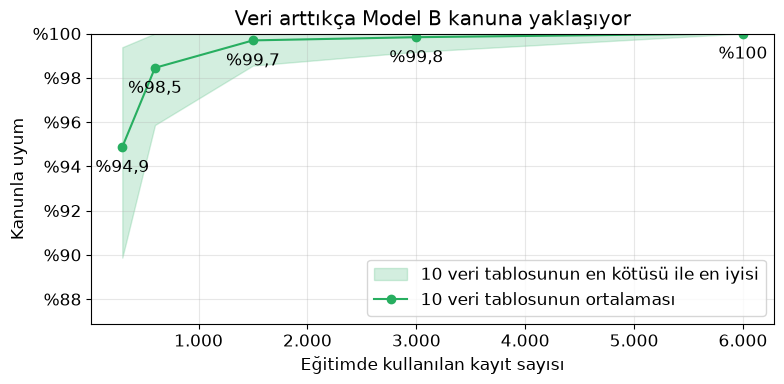

,Kayıt sayısı,Ortalama,En kötü,En iyi,Görülmemiş girdi payı,Görülmemiş girdilerde uyum
0,300,"%94,9","%89,9","%99,4","%39,6","%87,3"
1,600,"%98,5","%95,9",%100,"%25,5",%94
2,1.500,"%99,7","%98,6",%100,"%10,4","%97,2"
3,3.000,"%99,8","%99,2",%100,"%4,3","%96,3"
4,6.000,%100,%100,%100,"%1,4",%100


In [ ]:
sizes = [300, 600, 1500, 3000, 6000]
seeds = range(1, 11)
agreement = np.zeros((len(sizes), len(seeds)))
unseen_share_by_size = np.zeros_like(agreement)
unseen_agreement_by_size = np.full_like(agreement, np.nan)
grid_pairs = pd.MultiIndex.from_frame(grid[ENGINEERED])
# Each (size, seed) pair is a fresh table from the generator; the same law grid scores every model.
for i, size in enumerate(sizes):
    for j, seed in enumerate(seeds):
        table = add_features(dataset.generate_records(size, seed=seed))
        curve_model = DecisionTreeClassifier(random_state=42).fit(table[ENGINEERED], table[TARGET])
        hits = curve_model.predict(grid[ENGINEERED]) == grid["law"].to_numpy()
        new = ~grid_pairs.isin(pd.MultiIndex.from_frame(table[ENGINEERED]))
        agreement[i, j] = hits.mean()
        unseen_share_by_size[i, j] = new.mean()
        if new.any():  # a large table can cover every input; that run then has no unseen agreement (NaN)
            unseen_agreement_by_size[i, j] = hits[new].mean()
curve = pd.DataFrame({
    "Kayıt sayısı": sizes,
    "Ortalama": agreement.mean(axis=1),
    "En kötü": agreement.min(axis=1),
    "En iyi": agreement.max(axis=1),
    "Görülmemiş girdi payı": unseen_share_by_size.mean(axis=1),
    "Görülmemiş girdilerde uyum": np.nanmean(unseen_agreement_by_size, axis=1),  # skips the NaN runs above
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(curve["Kayıt sayısı"], curve["En kötü"], curve["En iyi"], color="#27ae60", alpha=0.2, label="10 veri tablosunun en kötüsü ile en iyisi")
ax.plot(curve["Kayıt sayısı"], curve["Ortalama"], marker="o", color="#27ae60", label="10 veri tablosunun ortalaması")
for size, mean in zip(curve["Kayıt sayısı"], curve["Ortalama"]):
    ax.annotate(percent_tr(mean), (size, mean), textcoords="offset points", xytext=(0, -18), ha="center")
ax.set_title("Veri arttıkça Model B kanuna yaklaşıyor")
ax.set_xlabel("Eğitimde kullanılan kayıt sayısı")
ax.set_ylabel("Kanunla uyum")
# Start the axis just under the worst run, so the gaps between sizes stay visible.
ax.set_ylim(curve["En kötü"].min() - 0.03, 1.0)
ax.set_yticks([t for t in ax.get_yticks() if curve["En kötü"].min() - 0.03 <= t <= 1.0])
ax.xaxis.set_major_formatter(lambda value, _: tl_tr(value))
ax.yaxis.set_major_formatter(lambda value, _: f"%{value * 100:.0f}")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/ogrenme_egrisi.png", dpi=160)
plt.show()
percent_columns = ["Ortalama", "En kötü", "En iyi", "Görülmemiş girdi payı", "Görülmemiş girdilerde uyum"]
curve.assign(**{c: curve[c].map(percent_tr) for c in percent_columns}, **{"Kayıt sayısı": curve["Kayıt sayısı"].map(tl_tr)})

**Eğriyi okurken dikkat.** Veri büyüdükçe kanun tablosundaki girdilerin çoğu eğitimde zaten görülmüş oluyor (tablodaki "Görülmemiş girdi payı" sütunu). Büyük tablolardaki yüksek uyum bu yüzden kısmen verinin her durumu kapsamasından geliyor. Kuralın öğrenilip öğrenilmediğinin asıl ölçüsü, son sütundaki görülmemiş girdilerde uyum.

**Yeni örnekler için tahmin.** Aşağıdaki fonksiyon modelin tahminini okunur bir cümleye çeviriyor. Ehliyet yaptırımı her ceza tutarına tek bir gün sayısı olarak bağlı; bu eşleşmeyi veriden okuyorum. Model kademe sınırlarında yanılabildiği için uygulama her tahmini kanun tablosuyla karşılaştırıyor ve fark varsa sürücüye söylüyor. Cevabı her zaman model veriyor; kanun tablosu yalnız denetliyor, çünkü amaç modelin ne öğrendiğini göstermek.

In [ ]:
# Each fine amount carries exactly one suspension length, so the model's fine is enough to look it up.
assert clean.groupby(TARGET)["ehliyet_geri_alma_gun"].nunique().max() == 1
SUSPENSION_BY_FINE = clean.groupby(TARGET)["ehliyet_geri_alma_gun"].first().to_dict()


def predict_fine(vehicle, road_type, speed):
    """Return the model's fine prediction for one measurement as a dictionary."""
    limit = rules.speed_limit(vehicle, road_type)
    row = add_features(pd.DataFrame([{"yol_tipi": road_type, "hiz_siniri": limit, "olculen_hiz": speed}]))
    fine = int(model.predict(row[ENGINEERED])[0])
    return {"limit": limit, "excess": speed - limit, "fine_tl": fine, "suspension_days": int(SUSPENSION_BY_FINE.get(fine, 0))}


def describe_prediction(vehicle, road_type, speed):
    """Turn a prediction into Turkish sentences for the driver, with a warning when the law disagrees."""
    result = predict_fine(vehicle, road_type, speed)
    message = f"{rules.VEHICLE_LABELS[vehicle]}, {rules.ROAD_LABELS[road_type].lower()} (sınır {result['limit']} km/s), {speed} km/s: "
    if result["fine_tl"] == 0:
        message += "Ceza almazsınız."
    else:
        message += (
            f"Ceza alırsınız. Tahminî ceza {tl_tr(result['fine_tl'])} TL; "
            f"tebliğden sonra {rules.EARLY_PAYMENT_PERIOD} içinde öderseniz {tl_tr(rules.early_payment_amount(result['fine_tl']))} TL."
        )
        if result["suspension_days"]:
            message += f" Ehliyetiniz {result['suspension_days']} gün geri alınır."
    law = rules.penalty_for(vehicle, road_type, speed)
    if (result["fine_tl"], result["suspension_days"]) != (law.fine_tl, law.suspension_days):
        message += f" Uyarı: kanun tablosuna göre ceza {tl_tr(law.fine_tl)} TL"
        message += f" ve {law.suspension_days} gün ehliyet geri alma" if law.suspension_days else ""
        message += "; model bu kademe sınırının yakınında yanılıyor."
    return message


examples = [
    ("otomobil", "yerlesim_yeri", 54),
    ("otomobil", "yerlesim_yeri", 63),
    ("panelvan", "otoyol", 132),
    ("otomobil", "bolunmus_yol", 165),
    ("motosiklet", "sehirlerarasi_cift_yonlu", 168),
    ("otomobil", "yerlesim_yeri", 96),
]
table = pd.DataFrame(
    [
        {"Araç": rules.VEHICLE_LABELS[v], "Yol": rules.ROAD_LABELS[r], "Hız (km/s)": s,
         "Tahmin (TL)": predict_fine(v, r, s)["fine_tl"], "Kanun (TL)": rules.penalty_for(v, r, s).fine_tl}
        for v, r, s in examples
    ]
)
for vehicle, road_type, speed in examples:
    print(describe_prediction(vehicle, road_type, speed))
print()
print(f"Tahmin, {len(table)} örneğin {int((table['Tahmin (TL)'] == table['Kanun (TL)']).sum())} tanesinde kanunla aynı.")
table.assign(**{c: table[c].map(tl_tr) for c in ["Tahmin (TL)", "Kanun (TL)"]})

Otomobil, yerleşim yeri içi (sınır 50 km/s), 54 km/s: Ceza almazsınız.
Otomobil, yerleşim yeri içi (sınır 50 km/s), 63 km/s: Ceza alırsınız. Tahminî ceza 4.000 TL; tebliğden sonra 1 ay içinde öderseniz 3.000 TL.
Panelvan, otoyol (sınır 110 km/s), 132 km/s: Ceza alırsınız. Tahminî ceza 6.000 TL; tebliğden sonra 1 ay içinde öderseniz 4.500 TL.
Otomobil, bölünmüş yol (sınır 110 km/s), 165 km/s: Ceza alırsınız. Tahminî ceza 20.000 TL; tebliğden sonra 1 ay içinde öderseniz 15.000 TL. Ehliyetiniz 30 gün geri alınır.
Motosiklet, şehirlerarası çift yönlü yol (sınır 80 km/s), 168 km/s: Ceza alırsınız. Tahminî ceza 30.000 TL; tebliğden sonra 1 ay içinde öderseniz 22.500 TL. Ehliyetiniz 90 gün geri alınır.
Otomobil, yerleşim yeri içi (sınır 50 km/s), 96 km/s: Ceza alırsınız. Tahminî ceza 15.000 TL; tebliğden sonra 1 ay içinde öderseniz 11.250 TL. Uyarı: kanun tablosuna göre ceza 20.000 TL ve 30 gün ehliyet geri alma; model bu kademe sınırının yakınında yanılıyor.

Tahmin, 6 örneğin 5 tanesinde ka

,Araç,Yol,Hız (km/s),Tahmin (TL),Kanun (TL)
0,Otomobil,Yerleşim yeri içi,54,0,0
1,Otomobil,Yerleşim yeri içi,63,4.000,4.000
2,Panelvan,Otoyol,132,6.000,6.000
3,Otomobil,Bölünmüş yol,165,20.000,20.000
4,Motosiklet,Şehirlerarası çift yönlü yol,168,30.000,30.000
5,Otomobil,Yerleşim yeri içi,96,15.000,20.000


**Tablonun yorumu.** İlk beş örnekte tahmin kanunla aynı ve cümle sürücünün bilmesi gereken her şeyi veriyor: ceza var mı, kaç TL, erken ödemede kaç TL, ehliyet geri alınır mı. Bu beş örnek, modelin kanundan ayrıldığı noktaların hiçbirine denk gelmiyor. Son örnek bilerek bir kademe sınırına konuldu (yerleşim yeri içinde 46 km/s aşım, ehliyet yaptırımının başladığı yer). Model burada yanılıyor ve uygulama bunu kanun tablosuyla yakalayıp açıkça söylüyor.

**Değerlendirme notu: model güvenilir mi?**

Kısa cevap: Model B kademelerin içinde güvenilir, kademe sınırlarının hemen yanında değil; bu yüzden uygulama her tahmini kanun tablosuyla denetliyor. Model A güvenilir değil, çünkü eğitim verisini ezberliyor.

- Model B test verisinde ve kanunla karşılaştırmada Model A'dan belirgin biçimde iyi. Fark algoritmadan değil, doğru sütunu vermekten geliyor: aşım sütunu, kanunun asıl sorusunu modele hazır veriyor.
- Model A eğitim verisini ezberliyor: eğitim doğruluğu ile test doğruluğu arasındaki fark bu aşırı öğrenmenin ölçüsü. Kanunla uyumu test doğruluğundan da düşük.
- Model B'nin kuralı öğrenip öğrenmediğinin asıl kanıtı yukarıdaki iki ölçüm: ağacın tam yerinde bulduğu kademe sınırları ve eğitimde hiç görmediği girdilerdeki uyum.
- Model B'nin kalan hataları kademe sınırlarının yakınında (her birinin uzaklığı yukarıda yazıyor). Ağaç eşiği gördüğü iki gözlemin ortasına koyuyor; sınırın tam yanında örnek yoksa eşik kayıyor. Öğrenme eğrisi bunun büyük ölçüde veri azlığından geldiğini destekliyor: eğitimde görülmemiş girdilerdeki uyum küçük tablolarda belirgin biçimde düşük, büyük tablolarda kanuna yakın (eğri tablosunun son sütunu).
- Zayıf yönler: veri gerçek ceza kayıtlarından değil, kanundan üretildi; gerçek dünyadaki ölçüm hatasını, levhayla değiştirilmiş yerel sınırları ve İçişleri Bakanlığının otomobiller için yerleşim yeri dışında 20 km/s'e kadar artırabildiği sınırları içermiyor. Yönetmeliğin 100. maddesi, hız sınırlayıcı bulundurması zorunlu otobüs ve minibüslerde bu cihazı 110 km/s'e, kamyon ve çekicilerde 99 km/s'e ayarlatıyor. Veri üretici bu sınırlayıcıyı hesaba katmıyor; veride sınırlayıcı çalışırken görülemeyecek hızda kayıtlar da var (sayısı Aşama 3'te). Örnekleri bu yüzden otomobil, panelvan ve motosikletten seçtim. Yönetmeliğin 101. maddesinde, sınırı %10'a kadar aşana işlem yapılmayacağını söyleyen ve hâlâ yürürlükte olan bir cümle var; kanunun km/s kademeleriyle çeliştiği yerde kanunu esas aldım.
- Olası iyileştirmeler: Model A'nın ezberini ağacın derinliğini (`max_depth`) ya da bir yapraktaki en az kayıt sayısını (`min_samples_leaf`) sınırlayarak azaltmak; kademe sınırlarının iki yanından daha çok örnek üretmek ya da eğitim verisini büyütmek; gerçek kayıtlar kamuya açılırsa modeli onlarla sınamak; tutarlar değişince veriyi yeniden üretmek. KTK Ek Madde 3 ve Kabahatler Kanunu 17/7'yi okuduğum kadarıyla tutarların 1 Ocak 2027'den itibaren her yıl yeniden değerleme oranıyla artması bekleniyor; bunu doğrulayan resmî bir duyuru bulamadım.

In [ ]:
# Save the numbers that the report and the slides use (before the interactive cell, so "Run all" writes them).
metrics = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(clean)),
    "missing_speed": int(raw["olculen_hiz"].isnull().sum()),
    "missing_weather": int(raw["hava"].isnull().sum()),
    "duplicates": int(raw.duplicated().sum()),
    "train_rows": int(len(X_eng_train)),
    "test_rows": int(len(X_eng_test)),
    "grid_rows": int(len(grid)),
    "models": {name: {k: round(float(v), 4) for k, v in values.items()} for name, values in results.items()},
    "model_b_mistakes": [[int(u), int(e)] for u, e in mistake_points],
    "model_b_disagreements": int(disagree.sum()),
    "mistake_distance_max": max(mistake_distances),
    "boundaries_total": len(boundaries),
    "boundaries_found": len(found),
    "unseen_share": round(float(unseen.mean()), 4),
    "unseen_agreement": round(float(unseen_agreement), 4),
    "seen_agreement": round(float(seen_agreement), 4),
    "learning_curve": [[int(s), round(float(m), 4), round(float(lo), 4), round(float(hi), 4)] for s, m, lo, hi in curve.iloc[:, :4].values],
    "curve_seeds": len(seeds),
    "curve_unseen_share": [round(float(v), 4) for v in curve["Görülmemiş girdi payı"]],
    "curve_unseen_agreement": [round(float(v), 4) for v in curve["Görülmemiş girdilerde uyum"]],
    "spelling_fixed": spelling_fixed,
    "limiter_rows": limiter_rows,
    "examples": [describe_prediction(v, r, s) for v, r, s in examples],
}
with open("figures/metrics.json", "w", encoding="utf-8") as handle:
    json.dump(metrics, handle, ensure_ascii=False, indent=2)
print(f"figures/metrics.json yazıldı ({len(metrics)} alan); rapor ve sunum sayılarını bu dosyadan alıyor.")

figures/metrics.json yazıldı (24 alan); rapor ve sunum sayılarını bu dosyadan alıyor.


## Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

Uygulama araç tipini, yol tipini ve hızınızı sorup anında tahmin üretir. Seçeneğin numarasını ya da adını ("Minibüs", "otoyol" gibi) yazabilirsiniz. İlk hücre uygulamayı tanımlar, ikinci hücre hazır cevaplarla örnek bir çalıştırma gösterir, son hücrede cevapları siz yazarsınız.

In [ ]:
TURKISH_TO_ASCII = str.maketrans("çğıöşüÇĞİÖŞÜ", "cgiosuCGIOSU")


def normalise(text):
    """Lower-case ASCII form, so 'Minibüs', 'MİNİBÜS' and 'minibus' compare equal."""
    return " ".join(text.translate(TURKISH_TO_ASCII).lower().replace("_", " ").split())


def ask(question, default, shown_default, read=None):
    """Read one answer from the keyboard (or from `read`); fall back to the default when no keyboard input is possible."""
    try:
        answer = (read or input)(f"{question} (varsayılan: {shown_default}): ").strip()
    except (EOFError, NotImplementedError):
        print(f"{question} (varsayılan: {shown_default}): (otomatik cevap) {shown_default}")
        return default
    return answer or default


def choose(question, options, default, read=None):
    """Ask until the answer is an option number, code or Turkish name; use the default after three misses."""
    keys = list(options)
    listing = ", ".join(f"{i} {label}" for i, label in enumerate(options.values(), start=1))
    accepted = {normalise(key): key for key in keys} | {normalise(label): key for key, label in options.items()}
    for _ in range(3):
        answer = normalise(ask(f"{question} [{listing}]", default, options[default], read))
        if answer.isdecimal() and 1 <= int(answer) <= len(keys):
            return keys[int(answer) - 1]
        if answer in accepted:
            return accepted[answer]
        print("Bu seçeneklerden birini yazın.")
    print(f"Üç denemede anlaşılamadı; {options[default]} seçildi.")
    return default


def read_speed(text):
    """Whole km/h between 1 and the plausible maximum, otherwise None."""
    text = text.strip()
    if not text.isdecimal():
        return None
    speed = int(text)
    return speed if 1 <= speed <= rules.MAX_PLAUSIBLE_SPEED else None


def run_fine_assistant(default_vehicle="otomobil", default_road="sehirlerarasi_cift_yonlu", default_speed="104", read=None):
    """Ask the three questions and print the prediction; `read` replaces the keyboard when given."""
    vehicle = choose("Araç tipi", rules.VEHICLE_LABELS, default_vehicle, read)
    road_type = choose("Yol tipi", rules.ROAD_LABELS, default_road, read)
    for _ in range(3):
        speed = read_speed(ask("Radarın ölçtüğü hız, km/s", default_speed, default_speed, read))
        if speed is not None:
            break
        print(f"1 ile {rules.MAX_PLAUSIBLE_SPEED} arasında bir tam sayı yazın.")
    else:
        speed = int(default_speed)
        print(f"Üç denemede anlaşılamadı; {speed} km/s kullanıldı.")
    print(describe_prediction(vehicle, road_type, speed))


def typed_answers(answers):
    """Stand-in for the keyboard: gives the answers in order and prints each question with its answer."""
    queue = iter(answers)

    def read(prompt):
        answer = next(queue)
        print(prompt + answer)
        return answer

    return read

In [ ]:
# Sample session: the answers come from this list instead of the keyboard.
run_fine_assistant(read=typed_answers(["Otomobil", "bölünmüş yol", "165"]))

Araç tipi [1 Otomobil, 2 Panelvan, 3 Kamyonet, 4 Motosiklet, 5 Minibüs, 6 Otobüs, 7 Kamyon] (varsayılan: Otomobil): Otomobil
Yol tipi [1 Yerleşim yeri içi, 2 Şehirlerarası çift yönlü yol, 3 Bölünmüş yol, 4 Otoyol] (varsayılan: Şehirlerarası çift yönlü yol): bölünmüş yol
Radarın ölçtüğü hız, km/s (varsayılan: 104): 165
Otomobil, bölünmüş yol (sınır 110 km/s), 165 km/s: Ceza alırsınız. Tahminî ceza 20.000 TL; tebliğden sonra 1 ay içinde öderseniz 15.000 TL. Ehliyetiniz 30 gün geri alınır.


**Sıra sizde.** Aşağıdaki hücreyi çalıştırıp üç soruyu cevaplayın. Klavye olmayan bir ortamda (otomatik çalıştırmada) uygulama varsayılan cevapları kullanır ve bunu "(otomatik cevap)" diye yazar.

In [ ]:
run_fine_assistant()

Araç tipi [1 Otomobil, 2 Panelvan, 3 Kamyonet, 4 Motosiklet, 5 Minibüs, 6 Otobüs, 7 Kamyon] (varsayılan: Otomobil): (otomatik cevap) Otomobil
Yol tipi [1 Yerleşim yeri içi, 2 Şehirlerarası çift yönlü yol, 3 Bölünmüş yol, 4 Otoyol] (varsayılan: Şehirlerarası çift yönlü yol): (otomatik cevap) Şehirlerarası çift yönlü yol
Radarın ölçtüğü hız, km/s (varsayılan: 104): (otomatik cevap) 104
Otomobil, şehirlerarası çift yönlü yol (sınır 90 km/s), 104 km/s: Ceza alırsınız. Tahminî ceza 2.000 TL; tebliğden sonra 1 ay içinde öderseniz 1.500 TL.


## Aşama 7: Özet

- **Problem:** Radar ölçümünden cezanın kesilip kesilmeyeceğini, tutarını ve ehliyet yaptırımını tahmin etmek.
- **Veri:** 2026 kanun kademelerinden üretilmiş radar kayıtları; bilerek bozulan satırlar temizlendi.
- **Yöntem:** Karar ağacı; ham sütunlarla kurulan model ile aşım ve yerleşim yeri sütunlarıyla kurulan model karşılaştırıldı, ikisi de kanunun kendisiyle sınandı.
- **Sonuç ve çıkarım:** Doğru özellik, modeli kanunun eşiklerine çok yaklaştırıyor; kalan hatalar eğitimde görülmemiş girdilerde ve kademe sınırlarının yanında, veri arttıkça da büyük ölçüde kapanıyor. Aynı algoritma, aldığı bilgiye göre ya eğitim verisini ezberliyor ya da kanunun kuralına yaklaşıyor.